# SafeVision AI — Cloud PPE Model Training (Google Colab + Google Drive)

This notebook trains a custom **YOLOv8** Personal Protective Equipment (PPE) detection model on Google Colab's free GPU (Tesla T4) and **automatically persists all checkpoints and exported weights to Google Drive**.

### Pipeline Overview:
1. **Mount Google Drive** ➔ Persistent storage (No data loss on disconnect)
2. **GPU Check** ➔ Verify NVIDIA CUDA acceleration
3. **Dependency Setup** ➔ Ultralytics, Roboflow, ONNX
4. **Dataset Download** ➔ Industrial PPE dataset saved directly in Drive
5. **YOLOv8 Fine-Tuning** ➔ 50 Epochs with automatic checkpointing
6. **Validation & Metrics** ➔ Confusion matrix, Precision, Recall, mAP50
7. **ONNX FP16 Quantization** ➔ Edge-optimized export (<25ms inference)
8. **Download Package** ➔ Bundles `best.pt` & `best.onnx` for local machine

In [1]:
# Cell 1: Mount Google Drive & Create Project Directory
import os
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Define dedicated directory in your Google Drive
PROJECT_DIR = '/content/drive/MyDrive/SafeVision_AI'
os.makedirs(PROJECT_DIR, exist_ok=True)

print(f"✅ Google Drive successfully mounted!")
print(f"📁 Persistent Project Folder: {PROJECT_DIR}")

Mounted at /content/drive
✅ Google Drive successfully mounted!
📁 Persistent Project Folder: /content/drive/MyDrive/SafeVision_AI


In [2]:
# Cell 2: Verify GPU Hardware & CUDA
!nvidia-smi

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Acceleration Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Assigned GPU: {torch.cuda.get_device_name(0)}")

Thu Nov 19 14:59:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# Cell 3: Install Required Dependencies
!pip install --upgrade ultralytics roboflow onnx onnxslim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 42.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 79.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [ultralytics]


In [4]:
# Cell 4: Download Industrial PPE Dataset directly into Google Drive
import os

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

if not os.path.exists(DATASET_DIR) or len(os.listdir(DATASET_DIR)) == 0:
    os.makedirs(DATASET_DIR, exist_ok=True)
    print("Downloading industrial PPE dataset to Google Drive...")
    !curl -L "https://universe.roboflow.com/ds/j3Vrhv0VpL?key=demo" > /content/ppe_dataset.zip
    !unzip -q /content/ppe_dataset.zip -d "{DATASET_DIR}"
    !rm /content/ppe_dataset.zip
    print(f"✅ Dataset successfully stored in: {DATASET_DIR}")
else:
    print(f"✅ Dataset already exists at {DATASET_DIR}. Skipping re-download!")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  5460  100  5460    0     0  50196      0 --:--:-- --:--:-- --:--:-- 51028
[/content/ppe_dataset.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/ppe_dataset.zip or
        /content/ppe_dataset.zip.zip, and cannot find /content/ppe_dataset.zip.ZIP, period.
✅ Dataset successfully stored in: /content/drive/MyDrive/SafeVision_AI/dataset


In [6]:
# Updated Cell 4 in your Colab Notebook:
import os
from ultralytics import YOLO

DATASET_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
model = YOLO('yolov8n.pt')

results = model.train(
    data=DATASET_URL,
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    project=os.path.join(PROJECT_DIR, "runs"),
    name="ppe_training_run",
    exist_ok=True,
    save=True,
    val=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_t

📊 Confusion Matrix:


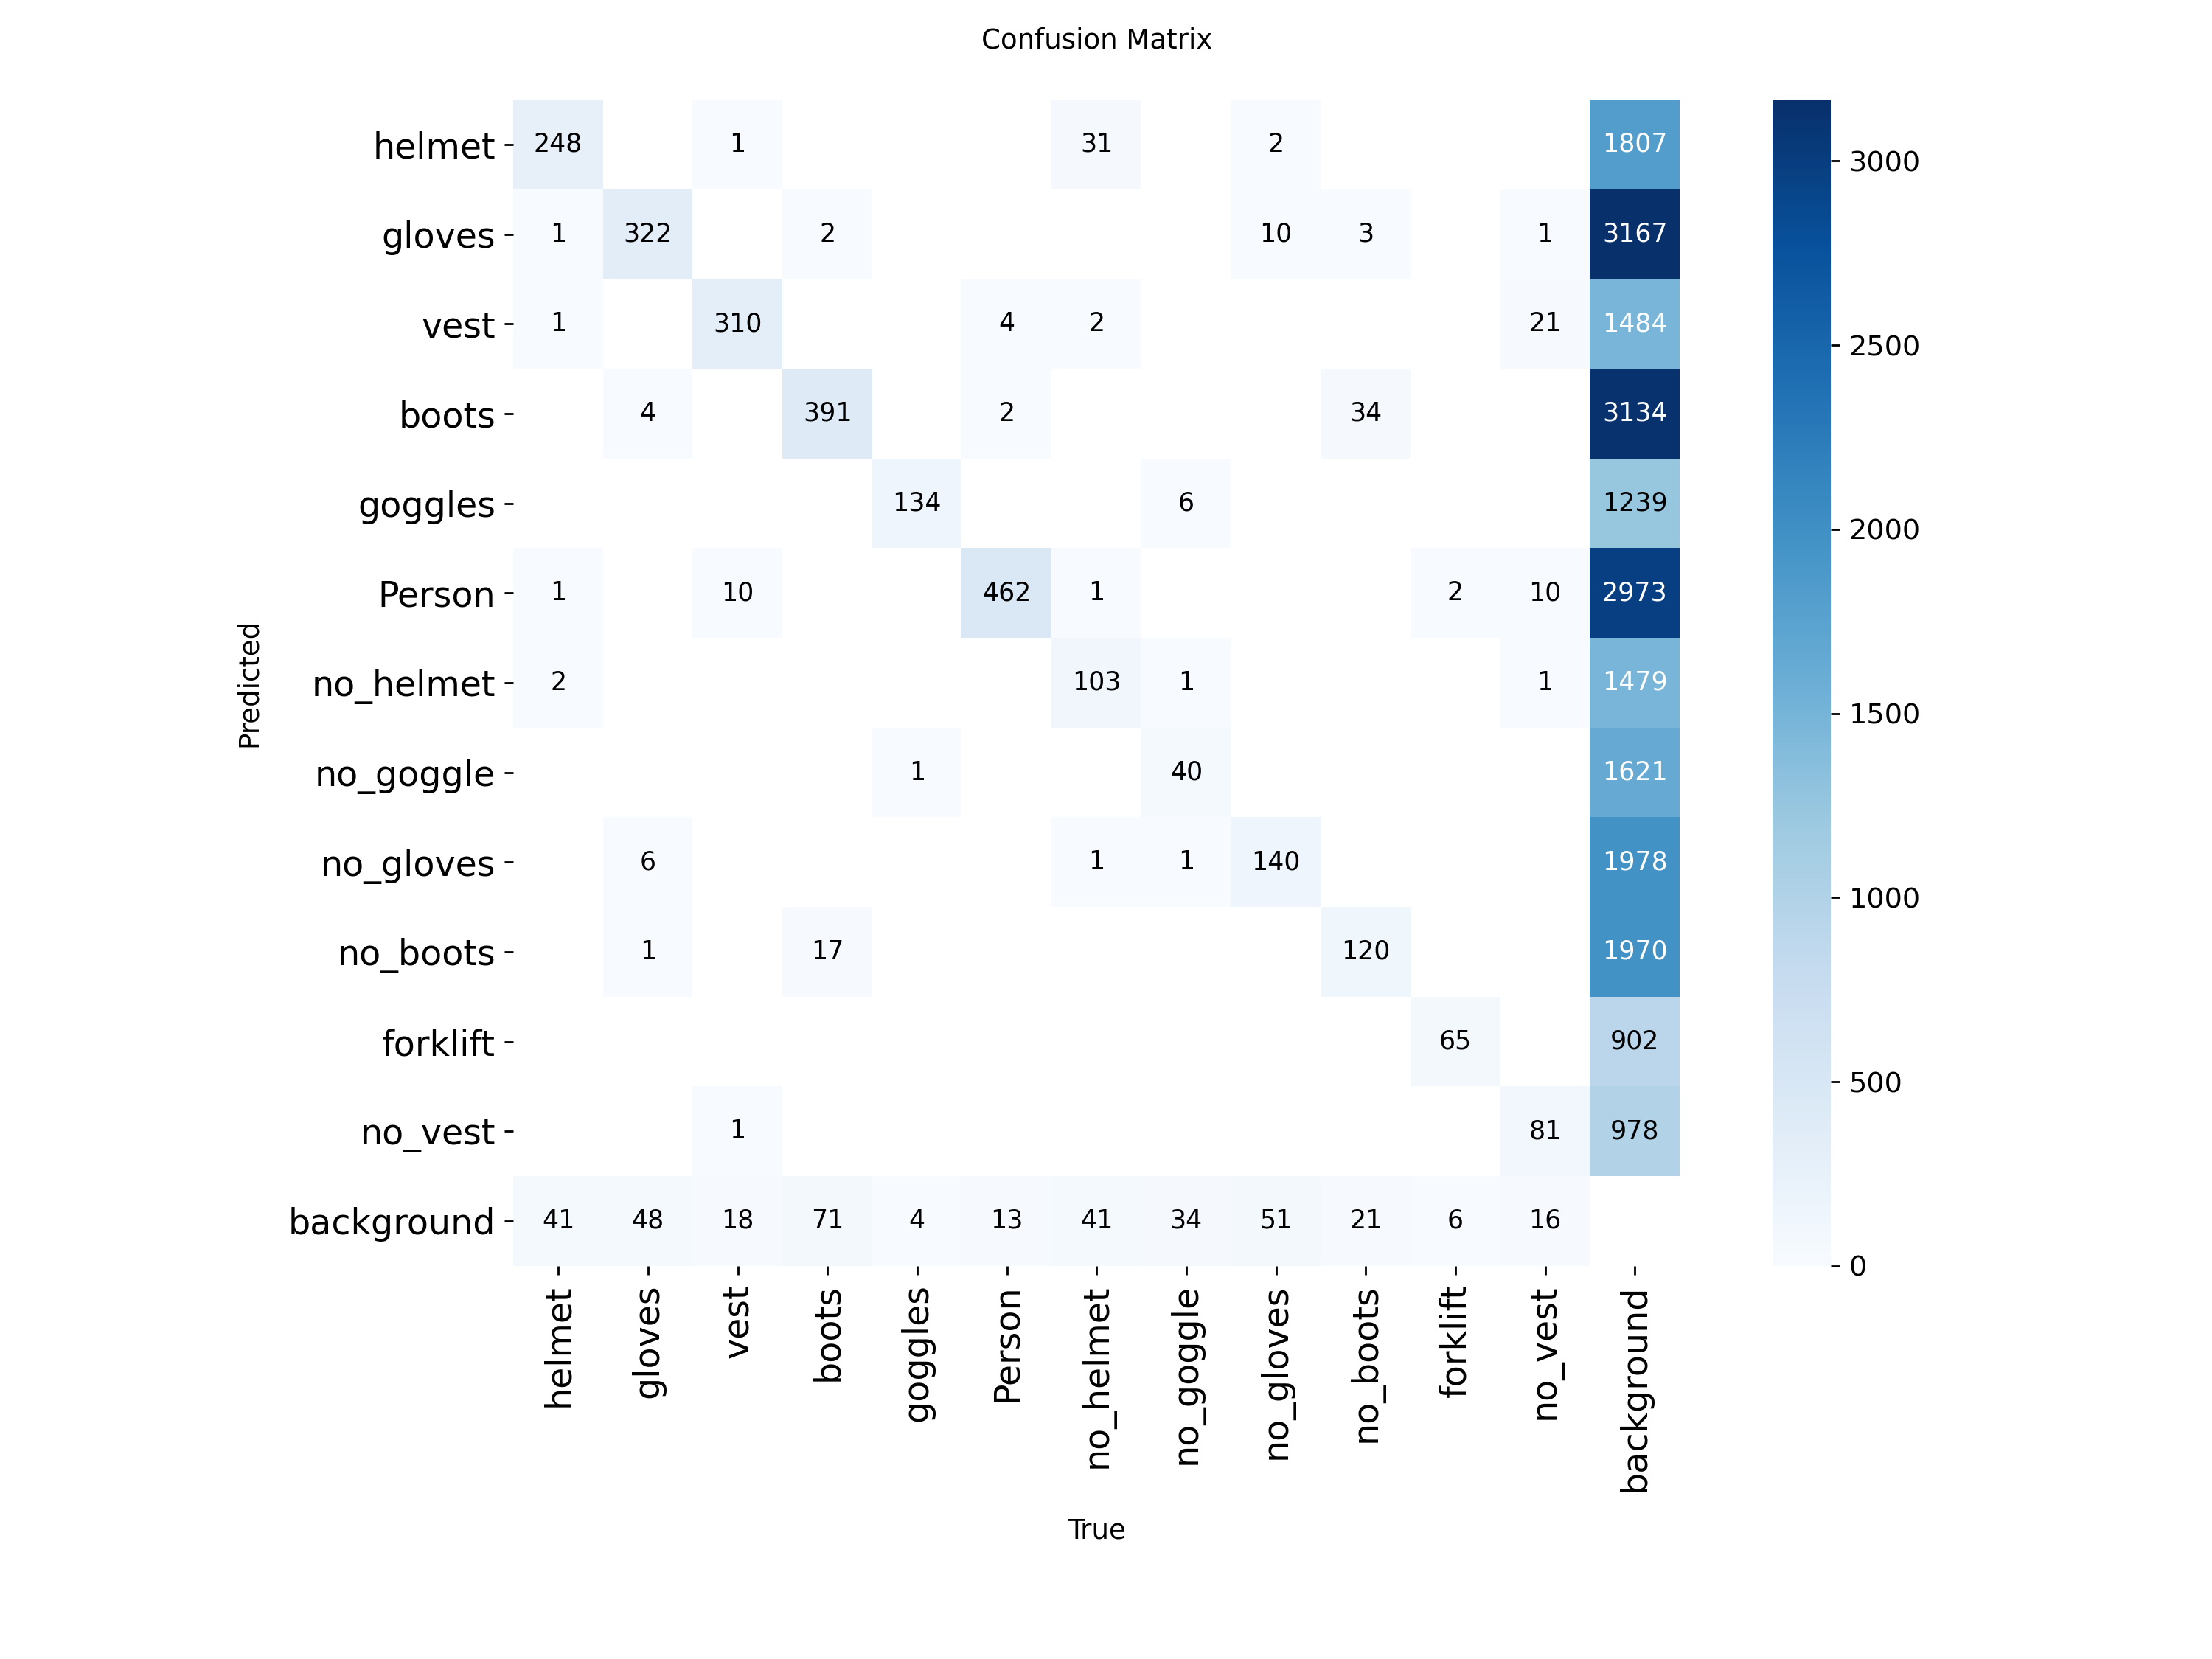

📈 Training Results (Loss & mAP Curves):


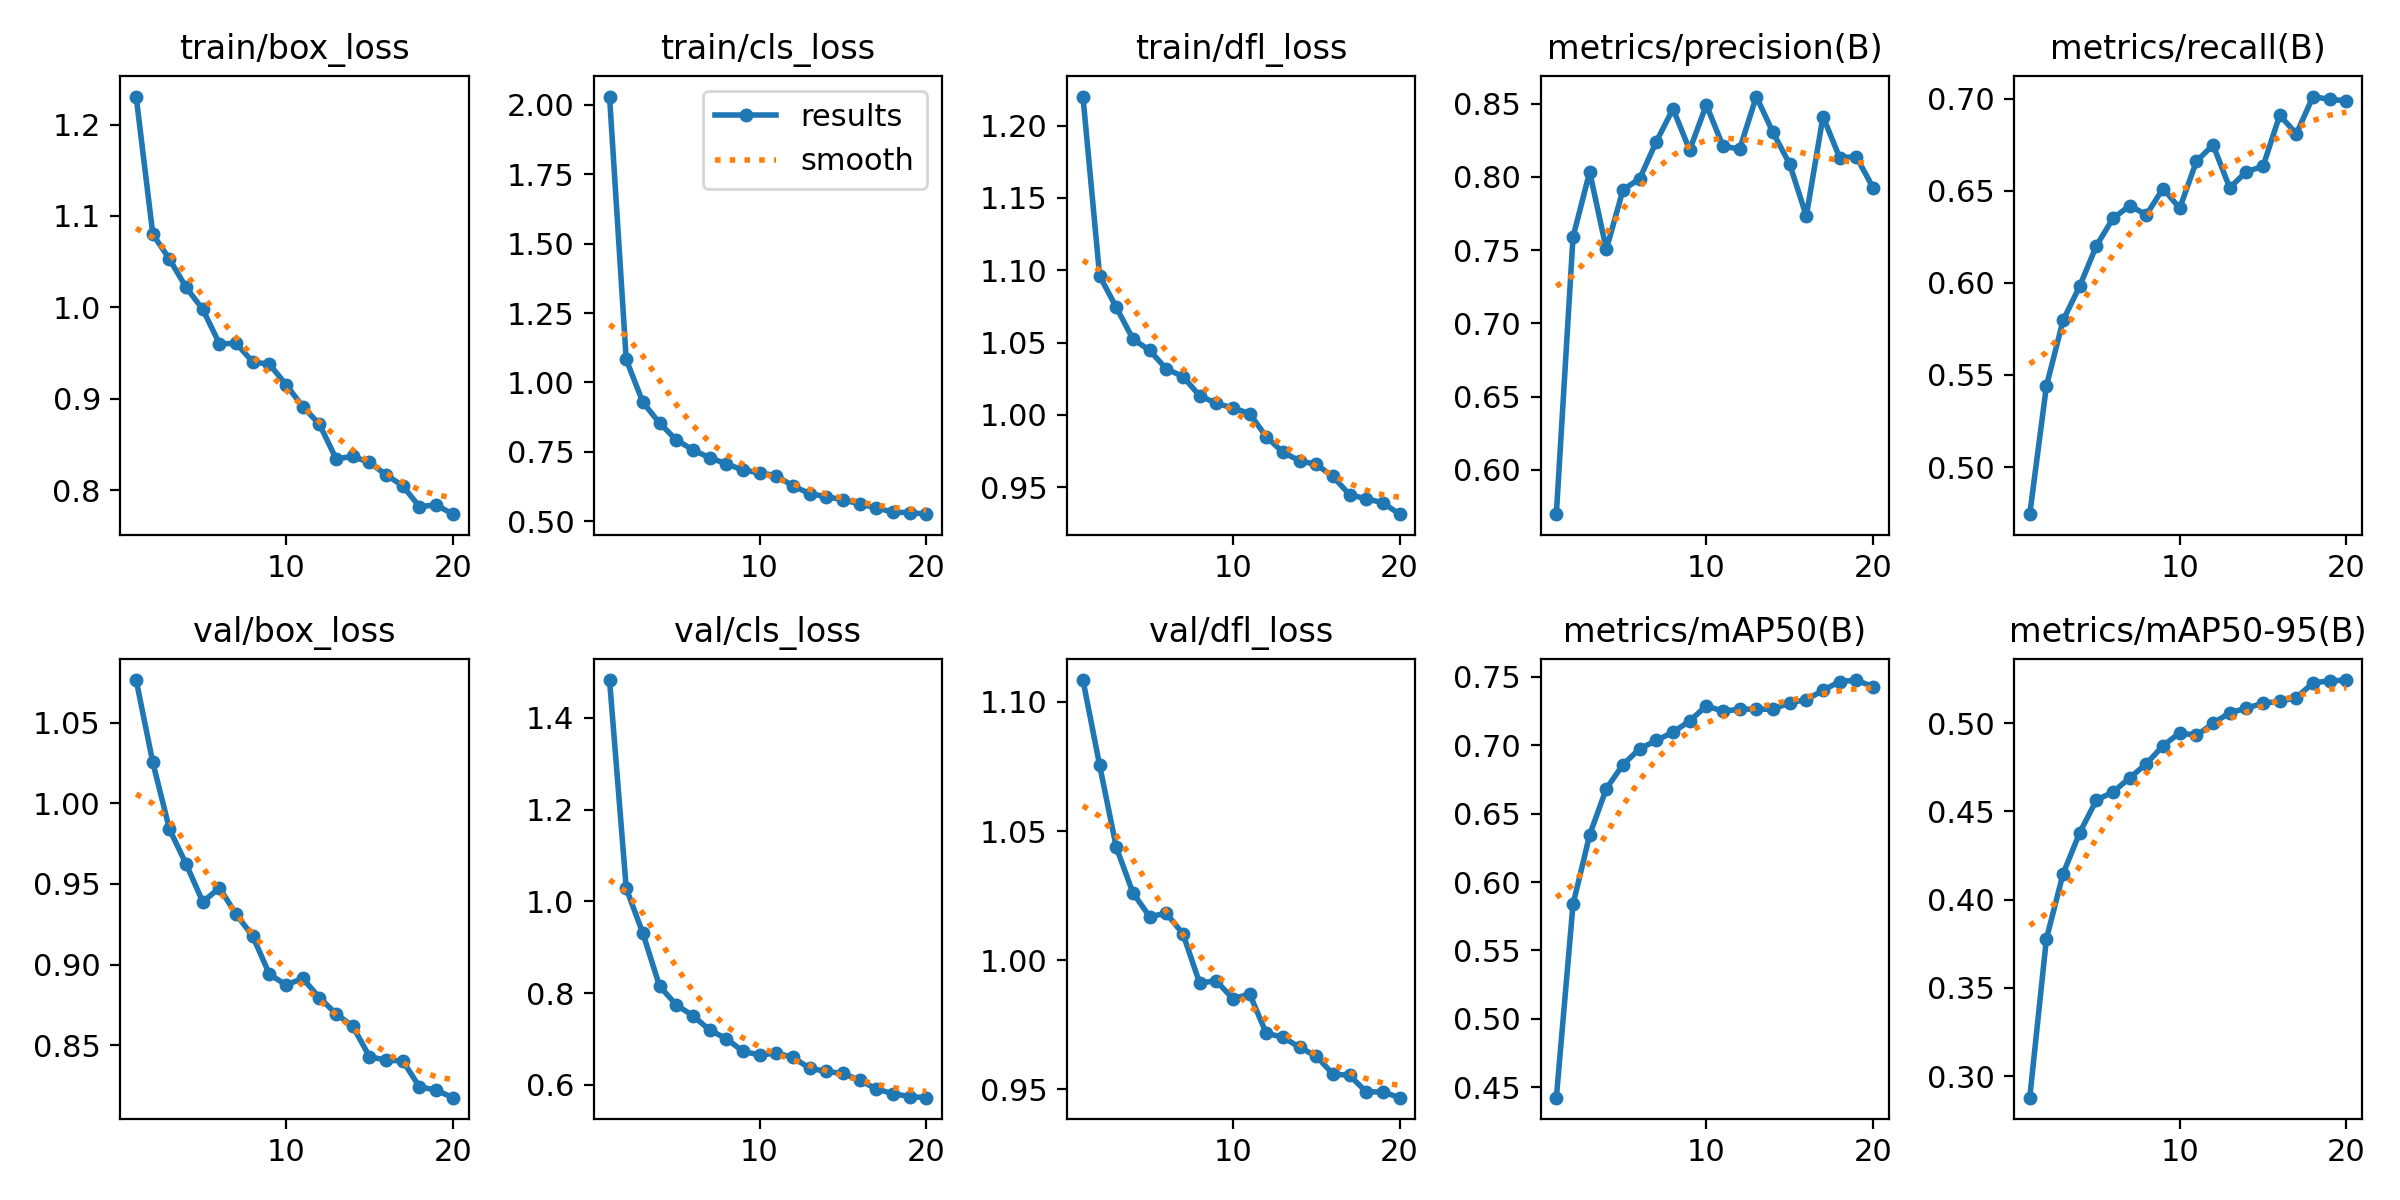

In [7]:
# Cell 6: Visualize Performance & Evaluation Metrics
import os
from IPython.display import Image, display

run_dir = os.path.join(PROJECT_DIR, "runs", "ppe_training_run")

# Display Confusion Matrix
cm_path = os.path.join(run_dir, "confusion_matrix.png")
if os.path.exists(cm_path):
    print("📊 Confusion Matrix:")
    display(Image(cm_path))

# Display mAP and Loss Curves
res_path = os.path.join(run_dir, "results.png")
if os.path.exists(res_path):
    print("📈 Training Results (Loss & mAP Curves):")
    display(Image(res_path))

In [8]:
# Cell 7: Export to ONNX FP16 for Edge Real-Time Inference
import os
from ultralytics import YOLO

best_weights = os.path.join(PROJECT_DIR, "runs", "ppe_training_run", "weights", "best.pt")
trained_model = YOLO(best_weights)

# Export half-precision (FP16) model with dynamic axes
onnx_export_path = trained_model.export(
    format="onnx",
    half=True,
    dynamic=True
)
print(f"✅ Exported ONNX FP16 Model: {onnx_export_path}")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/SafeVision_AI/runs/ppe_training_run/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 16, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 265ms
Prepared 1 package in 414ms
Installed 1 package in 8ms
 + onnxruntime==1.32.0

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...


In [9]:
# Cell 8: Package Trained Weights into Zip Bundle for Local Download
import os
import shutil
from google.colab import files

export_package_dir = os.path.join(PROJECT_DIR, "export_package")
os.makedirs(export_package_dir, exist_ok=True)

weights_dir = os.path.join(PROJECT_DIR, "runs", "ppe_training_run", "weights")
for f in ["best.pt", "best.onnx"]:
    src = os.path.join(weights_dir, f)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(export_package_dir, f))

zip_path = os.path.join(PROJECT_DIR, "SafeVision_AI_Weights.zip")
shutil.make_archive(zip_path.replace('.zip', ''), 'zip', export_package_dir)

print(f"📦 Package created at: {zip_path}")
print("Triggering automatic browser download...")
files.download(zip_path)

📦 Package created at: /content/drive/MyDrive/SafeVision_AI/SafeVision_AI_Weights.zip
Triggering automatic browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>